# 02g - Backtest sem vazamento — configuração atual: k = 15, peso igual na trajetória (D029)

Simula alguém **sentado na data de cada deck** prevendo a bandeira de M+1 a M+7 (regra do backtest no `CLAUDE.md`).

| Insumo | Fonte (disponível na data do deck) |
|---|---|
| Geração, ENA e custo marginal das 2.000 séries | saídas do deck (`ghtotsin`, `eafbm001–004`, `cmarg001–004`) |
| ANDE (+ consumo interno de Itaipu), PCH e carga dos submercados do mês-alvo | entradas do deck (`c_adic.dat`, `sistema.dat`) |
| GF_band, fatores de perda da CCEE, PLD mín/máx | boletim do mês do deck (publicado junto com o deck) |
| σ da probabilidade | só erros de previsões cujo mês-alvo terminou **antes** do mês do deck (mínimo de 8) |
| **ENA de referência** | **ORÁCULO**: ENA real de cada mês (será trocada pela previsão do ECMWF) |

**Método (mesma série):** **15 séries** pela trajetória de ENA do SIN do início do deck até o mês-alvo, com **peso igual em
toda a trajetória** (escolhidos só com os alvos de 2025; seção 8.9); GSF e PLD gatilho médios dessas séries; **cor = cor da média**; probabilidade de cada cor = X real ~ Normal(X médio, σ).

**Horizonte:** h = 1 a 7 meses após o mês do deck (7 = alcance da previsão sazonal do ECMWF) (o mês do próprio deck, h = 0, é decidido junto com a publicação do deck).

**O que é fora da amostra aqui:** ANDE/PCH/carga, GF_band, σ. **Escolhidos fora da amostra de teste:** k = 15 e peso igual (escolha com alvos de 2025;
os alvos de 2026 são teste). **Oráculo:** a ENA de referência.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import backtest, graficos, load, newave

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.index = base.index.to_period("M")
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
base["x_real"] = base.pld_gatilho_boletim * (1 - base.gsf_band_boletim).clip(lower=0)
ORD = ["Verde", "Amarela", "Vermelha 1", "Vermelha 2"]
backtest.decks_disponiveis()

[(2025, 2),
 (2025, 3),
 (2025, 4),
 (2025, 5),
 (2025, 6),
 (2025, 8),
 (2025, 11),
 (2025, 12),
 (2026, 1),
 (2026, 2),
 (2026, 3),
 (2026, 4),
 (2026, 5),
 (2026, 9)]

## 1. Previsões de cada deck

In [2]:
prev = pd.concat([backtest.prever_deck(a, m, base, k=15, meia_vida=np.inf) for a, m in backtest.decks_disponiveis()], ignore_index=True)
prev = prev.merge(base[["cor_oficial", "x_real", "gsf_band_boletim", "pld_gatilho_boletim"]],
                  left_on="alvo", right_index=True)
prev["erro_x"] = prev.x_real - prev.x_medio
prev.head()

,deck,alvo,h,gsf_medio,pld_medio,x_medio,cor_media,cor_oficial,x_real,gsf_band_boletim,pld_gatilho_boletim,erro_x
0,2025-02,2025-02,0,1.060,63.332,0.000,Verde,Verde,0.000,1.060,58.600,0.000
1,2025-02,2025-03,1,1.040,88.989,0.000,Verde,Verde,0.000,1.030,264.690,0.000
2,2025-02,2025-04,2,0.990,135.227,1.352,Verde,Verde,12.482,0.940,208.030,11.130
3,2025-02,2025-05,3,0.890,141.557,15.571,Verde,Amarela,41.121,0.830,241.890,25.550
4,2025-02,2025-06,4,0.770,215.958,49.670,Amarela,Vermelha 1,77.588,0.750,310.350,27.917


## 2. σ andando no tempo e probabilidade de cada cor

In [3]:
sigmas = {d: backtest.sigma_disponivel(prev, d) for d in prev.deck.unique()}
prev["sigma"] = prev.deck.map(lambda d: sigmas[d][0])
prev["n_erros_sigma"] = prev.deck.map(lambda d: sigmas[d][1])
probs = [newave.probabilidade_calibrada(x, s, g) if pd.notna(s) else pd.Series(np.nan, index=ORD)
         for x, s, g in zip(prev.x_medio, prev.sigma, prev.gsf_medio)]
for c in ORD:
    prev[f"p_{c}"] = [p[c] for p in probs]
prev["p_cor_real"] = [prev.loc[i, f"p_{c}"] for i, c in zip(prev.index, prev.cor_oficial)]
prev["p_cor_prevista"] = [prev.loc[i, f"p_{c}"] for i, c in zip(prev.index, prev.cor_media)]
obs = pd.DataFrame({c: (prev.cor_oficial == c).astype(float) for c in ORD})
prev["brier"] = ((prev[[f"p_{c}" for c in ORD]].to_numpy() - obs.to_numpy()) ** 2).sum(axis=1)
prev.loc[prev.sigma.isna(), "brier"] = np.nan
# referências ingênuas, conhecidas na data do deck
prev["cor_persistencia"] = prev.deck.map(base.cor_oficial)     # cor do mês do deck (já anunciada)
prev["cor_ano_anterior"] = (prev.alvo - 12).map(base.cor_oficial)
prev.to_parquet(load.DATA_PROCESSED / "backtest_newave_k15.parquet")
pd.DataFrame({"σ": {str(d): s for d, (s, n) in sigmas.items()}, "n erros": {str(d): n for d, (s, n) in sigmas.items()}})

,σ,n erros
2025-02,NaN,0
2025-03,NaN,0
2025-04,NaN,0
2025-05,NaN,1
2025-06,NaN,5
2025-08,12.159,15
2025-11,10.992,32
2025-12,10.871,37
2026-01,11.990,42
2026-02,11.937,43


## 3. Resultado por horizonte (h = 1 a 7)

In [4]:
t = prev[prev.h >= 1]
acerto = lambda col: (lambda s: (s == t.loc[s.index, "cor_oficial"]).mean())
resumo = t.groupby("h").agg(
    previsoes=("alvo", "size"), acerto_cor_media=("cor_media", acerto("cor_media")),
    acerto_persistencia=("cor_persistencia", acerto("cor_persistencia")),
    acerto_ano_anterior=("cor_ano_anterior", acerto("cor_ano_anterior")),
    erro_medio_gsf=("gsf_medio", lambda s: (s - t.loc[s.index, "gsf_band_boletim"]).abs().mean()),
    erro_medio_pld=("pld_medio", lambda s: (s - t.loc[s.index, "pld_gatilho_boletim"]).abs().mean()),
    com_probabilidade=("p_cor_real", "count"), prob_media_cor_real=("p_cor_real", "mean"), brier=("brier", "mean"))
total = pd.DataFrame([{
    "previsoes": len(t), "acerto_cor_media": (t.cor_media == t.cor_oficial).mean(),
    "acerto_persistencia": (t.cor_persistencia == t.cor_oficial).mean(),
    "acerto_ano_anterior": (t.cor_ano_anterior == t.cor_oficial).mean(),
    "erro_medio_gsf": (t.gsf_medio - t.gsf_band_boletim).abs().mean(),
    "erro_medio_pld": (t.pld_medio - t.pld_gatilho_boletim).abs().mean(),
    "com_probabilidade": t.p_cor_real.count(), "prob_media_cor_real": t.p_cor_real.mean(), "brier": t.brier.mean()}], index=["total"])
pd.concat([resumo, total])

,previsoes,acerto_cor_media,acerto_persistencia,acerto_ano_anterior,erro_medio_gsf,erro_medio_pld,com_probabilidade,prob_media_cor_real,brier
1,14,0.714,0.571,0.500,0.032,91.743,9,0.724,0.329
2,13,0.692,0.308,0.462,0.050,85.642,8,0.738,0.358
3,13,0.692,0.154,0.308,0.040,65.623,8,0.733,0.279
4,13,0.769,0.154,0.231,0.034,58.553,8,0.792,0.227
5,13,0.846,0.154,0.231,0.046,41.718,8,0.753,0.249
6,12,0.833,0.167,0.167,0.038,37.444,7,0.782,0.235
7,11,0.909,0.273,0.182,0.040,59.333,6,0.845,0.062
total,89,0.775,0.258,0.303,0.040,63.555,54,0.763,0.257


## 4. Matriz das previsões (deck × mês-alvo)

Célula = cor da média; o número é a probabilidade dessa cor (quando já há histórico para o σ); ✗ = errou.

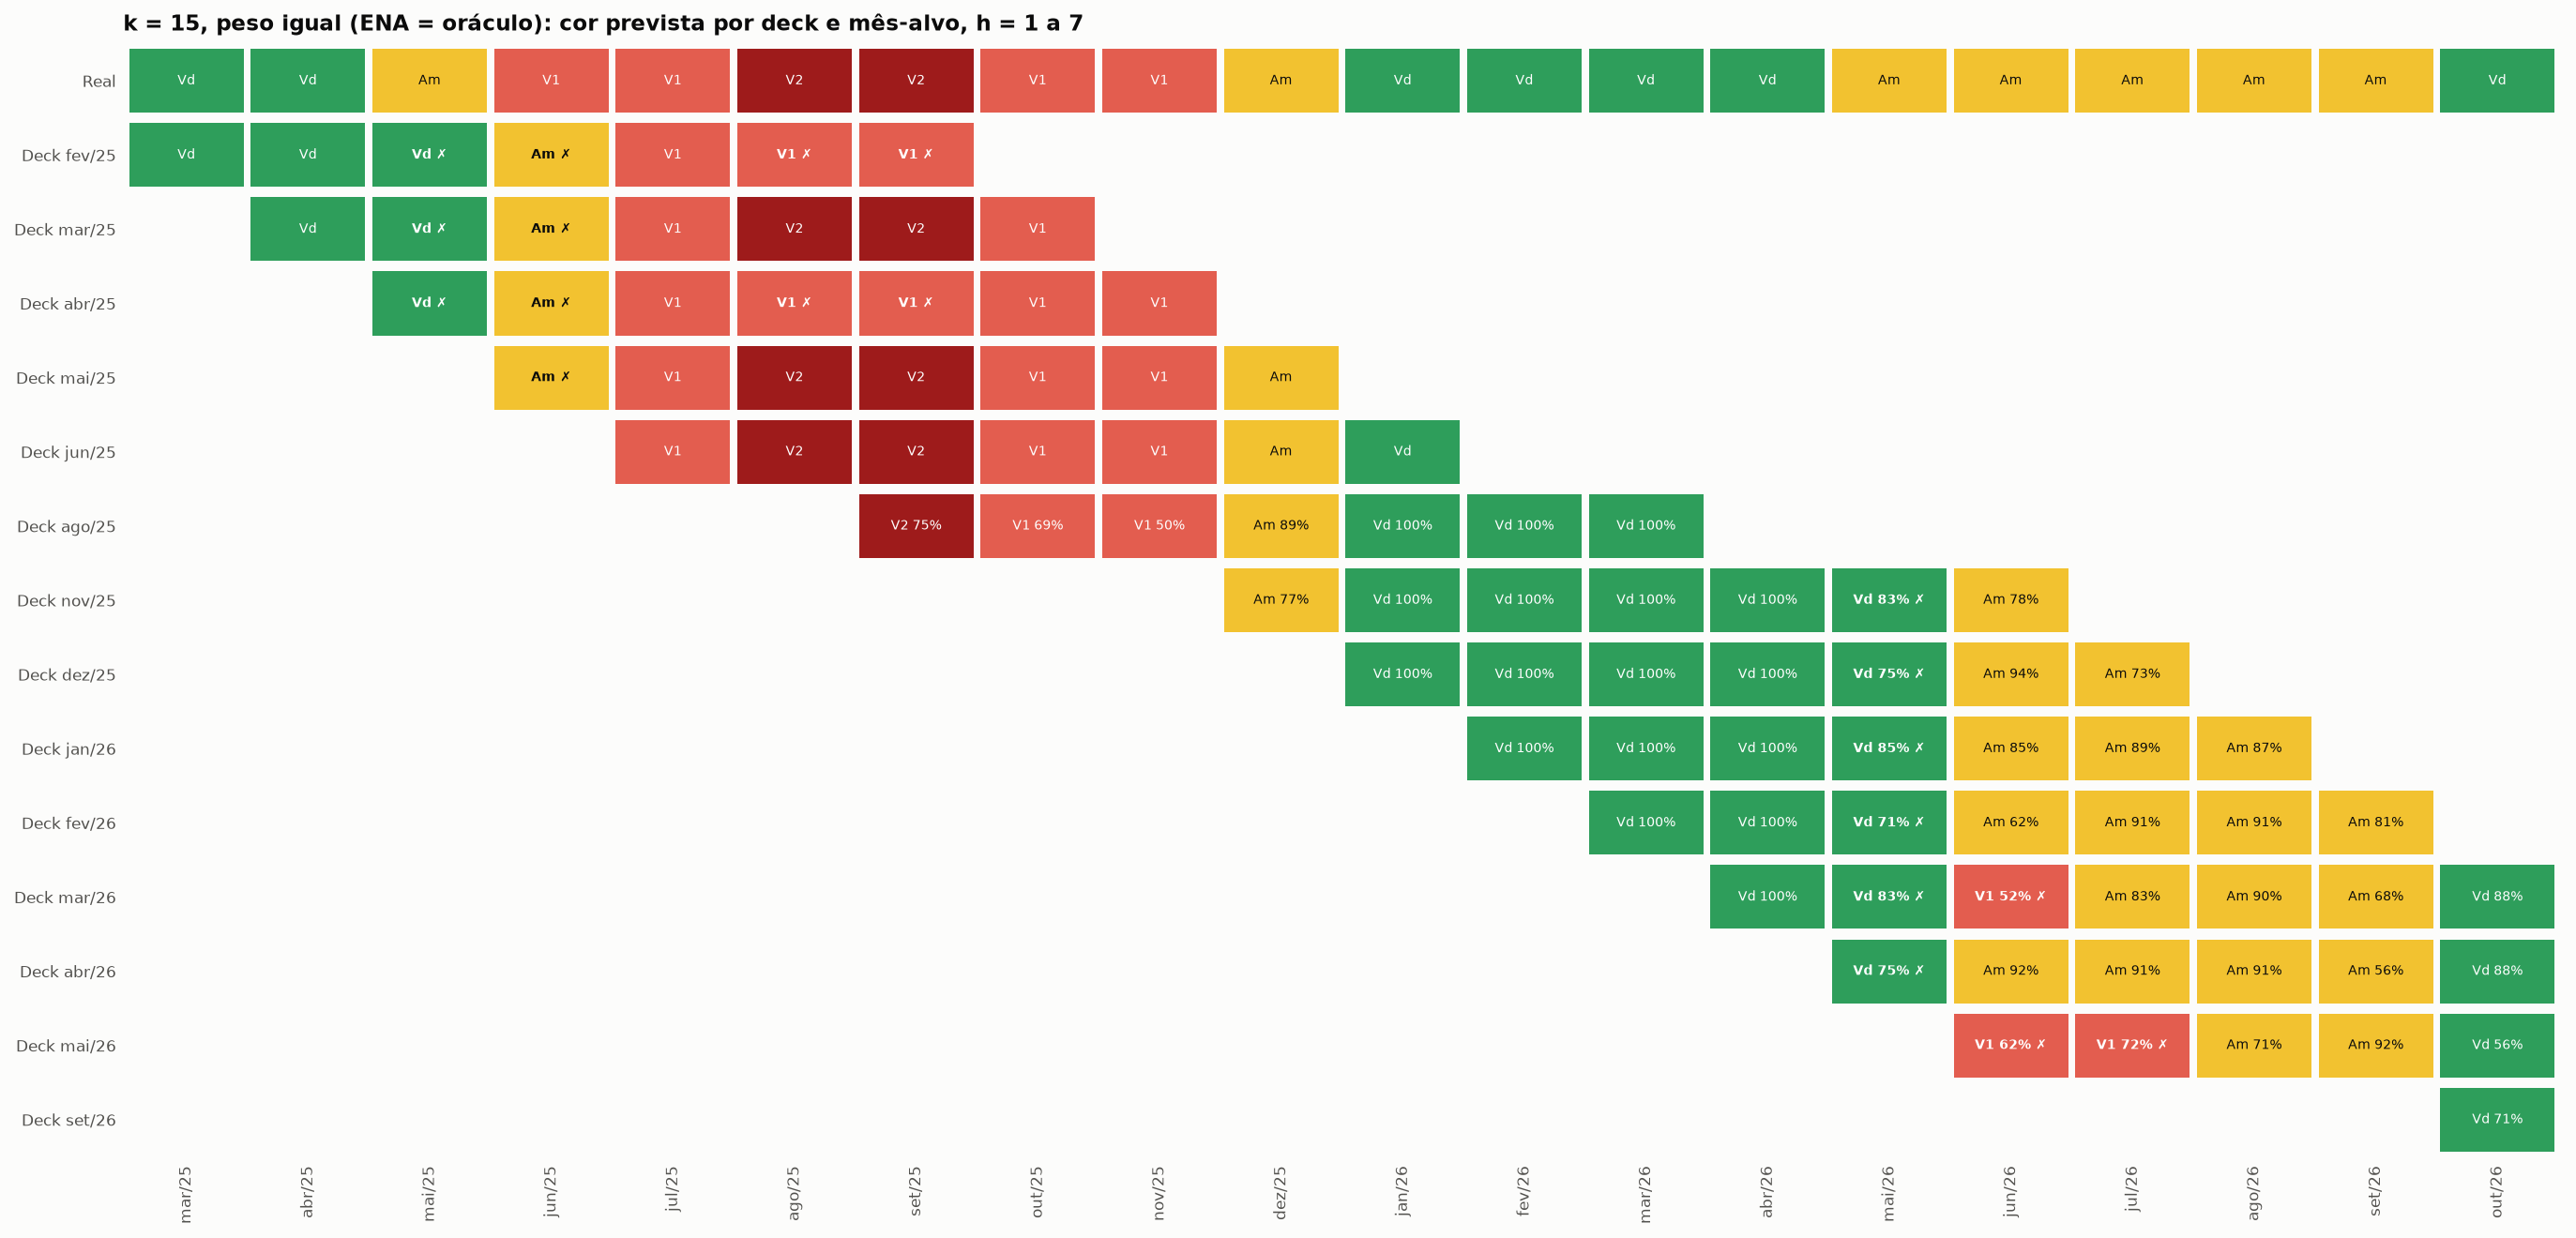

In [5]:
display(Image(graficos.matriz_backtest(
    t, "k = 15, peso igual (ENA = oráculo): cor prevista por deck e mês-alvo, h = 1 a 7",
    "backtest_k15_peso_igual/10_matriz_backtest.png")))

### Matriz ajustada: distribuição completa

Mesma metodologia; cada célula mostra a cor prevista (cor da média) e, embaixo, a probabilidade de cada cor (≥ 5%).

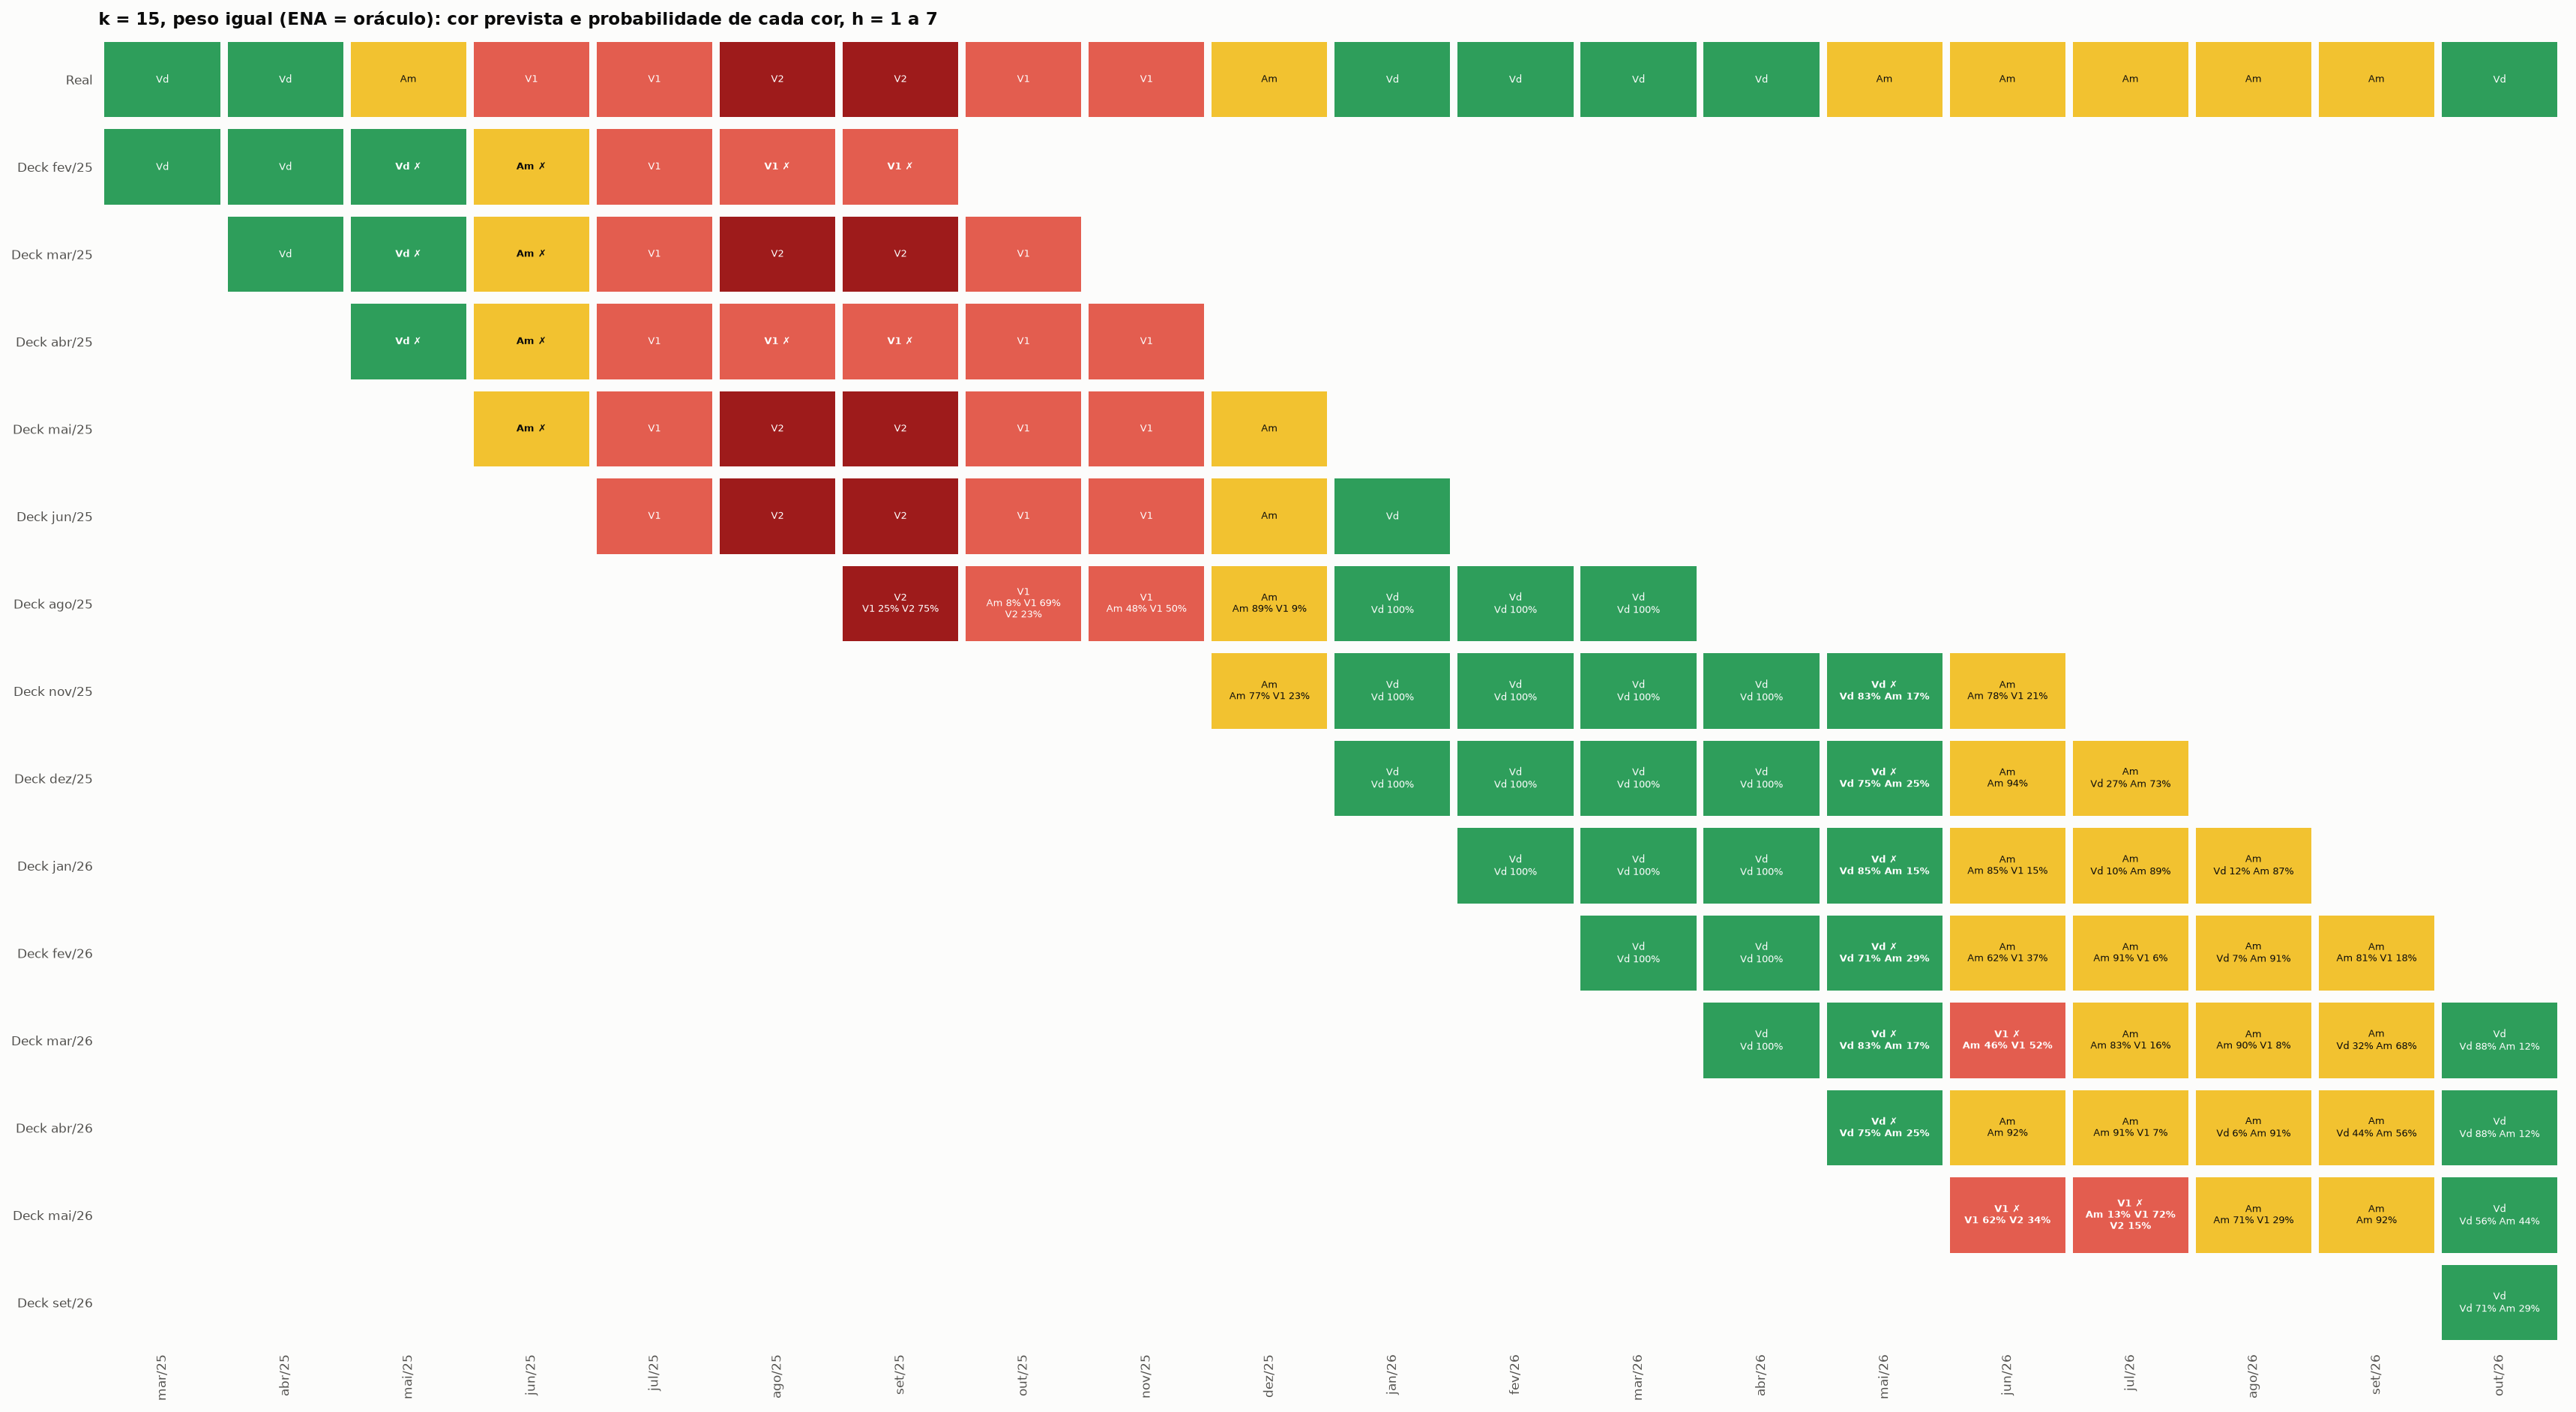

In [6]:
display(Image(graficos.matriz_backtest(
    t, "k = 15, peso igual (ENA = oráculo): cor prevista e probabilidade de cada cor, h = 1 a 7",
    "backtest_k15_peso_igual/10b_matriz_backtest_distribuicao.png", distribuicao=True)))

## 5. Onde estão os erros

In [7]:
erros = t[t.cor_media != t.cor_oficial]
print("erros por mês do ano do alvo:", erros.groupby(erros.alvo.dt.month).size().to_dict(), "de", len(erros))
print(f"nos erros: GSF previsto − real = {(erros.gsf_medio - erros.gsf_band_boletim).mean():+.3f} | "
      f"PLD previsto − real = {(erros.pld_medio - erros.pld_gatilho_boletim).mean():+.1f} R$/MWh")
erros[["deck", "alvo", "h", "cor_media", "cor_oficial", "gsf_medio", "gsf_band_boletim", "pld_medio", "pld_gatilho_boletim", "p_cor_real"]]

erros por mês do ano do alvo: {5: 9, 6: 6, 7: 1, 8: 2, 9: 2} de 20
nos erros: GSF previsto − real = +0.037 | PLD previsto − real = -46.0 R$/MWh


,deck,alvo,h,cor_media,cor_oficial,gsf_medio,gsf_band_boletim,pld_medio,pld_gatilho_boletim,p_cor_real
3,2025-02,2025-05,3,Verde,Amarela,0.890,0.830,141.557,241.890,NaN
4,2025-02,2025-06,4,Amarela,Vermelha 1,0.770,0.750,215.958,310.350,NaN
6,2025-02,2025-08,6,Vermelha 1,Vermelha 2,0.670,0.630,276.278,310.300,NaN
7,2025-02,2025-09,7,Vermelha 1,Vermelha 2,0.670,0.690,272.325,315.540,NaN
10,2025-03,2025-05,2,Verde,Amarela,0.880,0.830,228.919,241.890,NaN
11,2025-03,2025-06,3,Amarela,Vermelha 1,0.760,0.750,282.440,310.350,NaN
17,2025-04,2025-05,1,Verde,Amarela,0.880,0.830,175.412,241.890,NaN
18,2025-04,2025-06,2,Amarela,Vermelha 1,0.770,0.750,225.551,310.350,NaN
20,2025-04,2025-08,4,Vermelha 1,Vermelha 2,0.680,0.630,279.857,310.300,NaN
21,2025-04,2025-09,5,Vermelha 1,Vermelha 2,0.680,0.690,285.219,315.540,NaN


## 6. Comparação com a referência (k = 25, meia-vida 2; notebook 02f)

In [8]:
ref = pd.read_parquet(load.DATA_PROCESSED / "backtest_newave.parquet")
ref = ref[ref.h >= 1]
def resumo_cfg(d, nome):
    return {"configuração": nome, "previsões": len(d), "acerto": (d.cor_media == d.cor_oficial).mean(),
            "acerto alvos 2025": (d[d.alvo.dt.year == 2025].cor_media == d[d.alvo.dt.year == 2025].cor_oficial).mean(),
            "acerto decks 2026 (teste)": (d[d.deck.dt.year == 2026].cor_media == d[d.deck.dt.year == 2026].cor_oficial).mean(),
            "erro GSF": (d.gsf_medio - d.gsf_band_boletim).abs().mean(),
            "erro PLD": (d.pld_medio - d.pld_gatilho_boletim).abs().mean(),
            "erro X": (d.x_medio - d.x_real).abs().mean(),
            "prob. cor real": d.p_cor_real.mean(), "Brier": d.brier.mean()}
pd.DataFrame([resumo_cfg(ref, "referência: k = 25, meia-vida 2"), resumo_cfg(t, "atual: k = 15, peso igual")]).set_index("configuração").T

configuração,"referência: k = 25, meia-vida 2","atual: k = 15, peso igual"
previsões,89.000,89.000
acerto,0.708,0.775
acerto alvos 2025,0.615,0.718
acerto decks 2026 (teste),0.727,0.788
erro GSF,0.040,0.040
erro PLD,65.617,63.555
erro X,11.362,11.185
prob. cor real,0.750,0.763
Brier,0.279,0.257


In [9]:
m = ref[["deck", "alvo", "cor_media", "cor_oficial"]].merge(t[["deck", "alvo", "cor_media"]], on=["deck", "alvo"], suffixes=("_ref", "_novo"))
mud = m[m.cor_media_ref != m.cor_media_novo].copy()
mud["resultado"] = ["passou a acertar" if n == o else ("passou a errar" if r == o else "errou nos dois")
                    for r, n, o in zip(mud.cor_media_ref, mud.cor_media_novo, mud.cor_oficial)]
print(mud.resultado.value_counts().to_dict())
mud

{'passou a acertar': 6}


,deck,alvo,cor_media_ref,cor_oficial,cor_media_novo,resultado
4,2025-02,2025-07,Amarela,Vermelha 1,Vermelha 1,passou a acertar
11,2025-03,2025-08,Vermelha 1,Vermelha 2,Vermelha 2,passou a acertar
12,2025-03,2025-09,Vermelha 1,Vermelha 2,Vermelha 2,passou a acertar
37,2025-08,2025-11,Amarela,Vermelha 1,Vermelha 1,passou a acertar
75,2026-03,2026-09,Verde,Amarela,Amarela,passou a acertar
81,2026-04,2026-09,Verde,Amarela,Amarela,passou a acertar
